# The embedding problem: does a generator exist, and which one to use

**Question:** Is the pooled S&P one-year matrix the exponential of a valid generator, and if it is not, which repair keeps the generator's exponential closest to the matrix and what does the choice do to a five-year PD?

- **Level:** 2, The method in practice
- **Prerequisites:** notebook 02 of this topic (the pooled matrix and the EM generator)
- **Reading time:** about 35 minutes

## Objectives

By the end of this notebook you can:

- say what the embedding problem asks (is a one-year matrix the exponential of a generator?) and why it matters to a PD at a horizon other than one year;
- run Israel, Rosenthal and Wei's checks on a real matrix and read each: the convergence of the log series, the three conditions that exclude an exact generator, stochastic monotonicity;
- compute the matrix logarithm by its series, find its negative off-diagonal entries and repair them with the diagonal, the weighted and the Jarrow-Lando-Turnbull adjustments;
- compare the repairs and the EM generator by the L1 distance of the exponential to the matrix, and by the PD each gives at one and five years;
- read the nine distances Israel et al. print beside the engine's recomputation, and say which one does not reproduce and why.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.0.1 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.transitions import embedding, estimators
from riskvalidation.transitions.em import em_generator
from scipy.linalg import expm

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed files of case C04:

- `data/derived/C04/sp.json`: the S&P pooled one-year matrix of notebook 02 (`outputs.pooled.matrix`, withdrawals removed, seven grades and default) and what the case computed from it: `outputs.embedding` (the diagnostics) and `outputs.generators` (the diagonal, weighted, JLT and EM generators with their L1 distances and PDs at one and five years). Source: ESMA CEREP (licence class `mirror-allowed`; https://registers.esma.europa.eu/cerep-publication/).
- `data/derived/C04/published.json`: Israel, Rosenthal and Wei's printed L1 distances for three agency matrices, each with the value the engine recomputes. The paper's matrices are not committed (the artifact keeps only the distances), so this part of the notebook reads the comparison and cannot rerun it.

The next cell loads both files and names the cohorts the pooled matrix is built from.

In [2]:
# Load the two artifacts (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
C04 = ROOT / "data" / "derived" / "C04"
load = lambda name: json.loads((C04 / name).read_text(encoding="utf-8"))
sp, published = load("sp.json"), load("published.json")
out = sp["outputs"]
states = out["states"]
cohorts = out["cohorts"]

print("states:", states)
print("annual cohorts:", len(cohorts), "| engine that baked the artifacts:",
      sp["provenance"]["riskvalidation_version"])

states: ['AAA', 'AA', 'A', 'BBB', 'BB', 'B', 'CCC-C', 'D']
annual cohorts: 26 | engine that baked the artifacts: 1.0.1


## Method

### Step 0: the pooled one-year matrix

Everything below starts from one matrix, the S&P pooled one-year matrix of notebook 02: the 26 annual count tables added up, the withdrawn ratings removed year by year, each row divided by its total. The next cell rebuilds it with the engine's `pooled_cohort` and prints the diagonal, the probability of staying in the grade for a year (default is absorbing, so its entry is one).

In [3]:
# Pool the 26 annual tables into the one-year matrix the rest of the notebook works on
tables = [np.vstack([np.array(c["counts"], dtype=float), np.zeros(len(states))]) for c in cohorts]
gone = [np.append(np.array(c["withdrawn"], dtype=float), 0.0) for c in cohorts]
P = estimators.pooled_cohort(tables, gone, treatment="exclude")["matrix"]

print("matrix:", P.shape)
print("probability of staying a year:", ", ".join(f"{s} {v:.4f}" for s, v in zip(states, np.diag(P))))

matrix: (8, 8)
probability of staying a year: AAA 0.8227, AA 0.8901, A 0.9399, BBB 0.9294, BB 0.8735, B 0.8692, CCC-C 0.7148, D 1.0000


### Step 1: can this matrix have a generator?

A rating matrix $P$ is observed over one year, but a bank needs PDs at three or five years, and a continuous-time model needs a **generator** $Q$: non-negative off-diagonal entries (rates of moving), rows summing to zero, with $\exp(Q) = P$. The embedding problem asks whether such a $Q$ exists. Israel, Rosenthal and Wei (2001) give three tools, all in the engine's `embedding_diagnostics`:

- **Theorem 1.** With $S = \max\{(a-1)^2 + b^2 : a + bi \text{ an eigenvalue of } P\}$, if $S < 1$ the series $\tilde Q = (P - I) - \tfrac12 (P-I)^2 + \tfrac13 (P-I)^3 - \dots$ converges and $\exp(\tilde Q) = P$ exactly, with rows summing to zero. Theorem 2: if every $p_{ii} > 1/2$ then $S < 1$, and the generator, if any, is unique.
- **Theorem 3.** No exact generator exists if (a) $\det P \le 0$, (b) $\det P > \prod_i p_{ii}$, or (c) some state $j$ is reachable from $i$ while $p_{ij} = 0$.
- **Lemma 1** (Jarrow, Lando and Turnbull). The chain is stochastically monotone when $\sum_{j \ge k} p_{ij}$ does not decrease in $i$ for every $k$: a worse grade is never safer.

The next cell runs the diagnostics and prints them as a table, with the pairs of condition (c) named by their states.

In [4]:
# Run the embedding diagnostics of Israel, Rosenthal and Wei on the pooled matrix
diag = embedding.embedding_diagnostics(P)
pairs = [f"{states[i]} to {states[j]}" for i, j in diag["theorem3_c"]]

print(f"S (Theorem 1): {diag['S']:.4f} | series converges: {diag['series_converges']}")
print(f"every diagonal entry above 1/2: {diag['all_diagonal_above_half']}")
print(f"det P = {diag['det']:.4f} | product of the diagonal = {diag['prod_diagonal']:.4f}")
print("Theorem 3 (a) det <= 0:", diag["theorem3_a"], "| (b) det > prod p_ii:", diag["theorem3_b"])
print("Theorem 3 (c) reachable with p_ij = 0:", len(pairs), pairs)
print("an exact generator is excluded:", diag["exact_generator_excluded"])
print("stochastically monotone:", diag["stochastically_monotone"],
      "|", len(diag["monotonicity_violations"]), "violations")

S (Theorem 1): 0.1209 | series converges: True
every diagonal entry above 1/2: True
det P = 0.3364 | product of the diagonal = 0.3471
Theorem 3 (a) det <= 0: False | (b) det > prod p_ii: False
Theorem 3 (c) reachable with p_ij = 0: 6 ['AAA to BBB', 'AAA to BB', 'AAA to D', 'B to AAA', 'CCC-C to AAA', 'CCC-C to AA']
an exact generator is excluded: True
stochastically monotone: False | 4 violations


Read it: S is well below one, so the series converges and the matrix has a candidate generator $\tilde Q$, and every diagonal entry is above 1/2, so a generator, if there were one, would be unique. The determinant sits between zero and the product of the diagonal, so conditions (a) and (b) do not exclude it. Condition (c) does, in six pairs: AAA reaches BBB, BB and default in several steps and B, CCC-C reach the top grades, while the pooled one-year matrix has zero for each of those moves. So **no exact generator exists**, and the chain also breaks monotonicity in four cells. This is the usual situation with an empirical matrix. What the diagnostics do not give is the size of the damage: the question becomes which valid generator to use, and how far its exponential is from the matrix.

### Step 2: the matrix logarithm by its series

The engine's `log_series` sums Theorem 1's series until a term is below $10^{-14}$ and also reports its distance to SciPy's `logm`, which computes the principal logarithm by another algorithm. The result $\tilde Q$ is the unique candidate, and it is a generator only if no off-diagonal entry is negative. The next cell prints how many terms it needed, how well the exponential of $\tilde Q$ gives $P$ back, and how many off-diagonal entries are negative.

In [5]:
# Sum the log series, exponentiate it back, and count the negative off-diagonal entries
series = embedding.log_series(P)
q_tilde = series["generator"]
off = ~np.eye(len(states), dtype=bool)
negative = off & (q_tilde < -1e-12)
corner = np.unravel_index(np.argmin(np.where(off, q_tilde, 0.0)), q_tilde.shape)

print("terms summed:", series["terms"], "| distance to SciPy logm:", f"{series['distance_to_logm']:.1e}")
print("largest entry of exp(Q~) - P:", f"{np.abs(expm(q_tilde) - P).max():.1e}")
print("negative off-diagonal entries:", int(negative.sum()))
print("most negative:", states[corner[0]], "to", states[corner[1]], round(float(q_tilde[corner]), 4))
print("Q~ is a generator:", embedding.is_generator(q_tilde))

terms summed: 28 | distance to SciPy logm: 1.7e-15
largest entry of exp(Q~) - P: 1.4e-15
negative off-diagonal entries: 9
most negative: CCC-C to BB -0.0036
Q~ is a generator: False


The next cell draws where the negative entries sit, one cell of the matrix per square, in thousandths of a unit of rate per year.

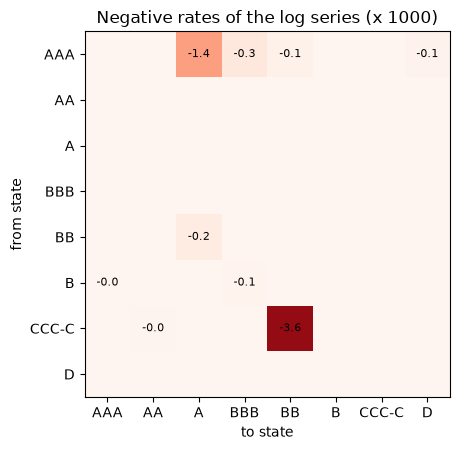

In [6]:
# Draw the negative off-diagonal entries of Q~ (rate per year times 1000), zero elsewhere
shown = np.where(negative, 1000 * q_tilde, 0.0)
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.imshow(shown, cmap="Reds_r", vmin=-4, vmax=0)
for i, j in zip(*np.nonzero(negative)):
    ax.text(j, i, f"{shown[i, j]:.1f}", ha="center", va="center", fontsize=8)
ax.set_xticks(range(len(states)))
ax.set_xticklabels(states)
ax.set_yticks(range(len(states)))
ax.set_yticklabels(states)
ax.set_xlabel("to state")
ax.set_ylabel("from state")
ax.set_title("Negative rates of the log series (x 1000)")
fig.tight_layout()
plt.show()

The series converges, sits 1.7e-15 from SciPy's logarithm and gives the matrix back to 1.4e-15, so the arithmetic is sound; the problem is the model. Nine off-diagonal entries are negative, and eight of them sit in the rows of AAA, B and CCC-C, the rows that condition (c) singled out: where the matrix records a move as impossible in one year, the logarithm answers with a negative rate for a neighbouring one. The figure shows that the damage is concentrated: the largest is CCC-C to BB at -3.6 per thousand, then AAA to A at -1.4, and the other seven are below 0.4 in absolute value. It does not show how much a repair costs, which is the next step.

### Step 3: three ways to repair it

Each repair removes the negative entries and keeps the row sums at zero, at the price of $\exp(Q) \neq P$:

- **Diagonal adjustment**, equation (2): $q_{ij} = \max(\tilde q_{ij}, 0)$ for $j \ne i$ and $q_{ii} = \tilde q_{ii} + \sum_{j \ne i} \min(\tilde q_{ij}, 0)$. The negative mass goes to the diagonal.
- **Weighted adjustment**, equation (2'): the negative entries are set to zero and their total $B_i = \sum_{j \ne i} \max(-\tilde q_{ij}, 0)$ is taken from the entries of the right sign in proportion to their size, $q_{ij} = \tilde q_{ij} - B_i |\tilde q_{ij}| / G_i$ with $G_i = |\tilde q_{ii}| + \sum_{j \ne i} \max(\tilde q_{ij}, 0)$.
- **JLT**, equation (3) of Jarrow, Lando and Turnbull, which does not use the series: it assumes at most one transition a year, $q_{ii} = \log p_{ii}$ and $q_{ij} = p_{ij} \log(p_{ii}) / (p_{ii} - 1)$.

Israel et al. measure each repair by the L1 distance $\sum_{ij} |P - \exp(Q)|_{ij}$.

The next cell follows the worst row, CCC-C, through the three formulas and then prints, for each repair, whether the result is a valid generator and its L1 distance.

In [7]:
# The three repairs, the CCC-C row through each, and the validity and L1 distance of every result
q_diag = embedding.diagonal_adjustment(q_tilde)
q_weighted = embedding.weighted_adjustment(q_tilde)
q_jlt = embedding.jlt_generator(P)
repairs = {"Q~ (series)": q_tilde, "diagonal (2)": q_diag, "weighted (2')": q_weighted, "JLT (3)": q_jlt}
row = len(states) - 2

print(f"{'':20s}" + "".join(f"{s:>9s}" for s in states))
for label, q in repairs.items():
    print(f"{label:20s}" + "".join(f"{v:9.5f}" for v in q[row]))
print(f"{'':20s}{'valid generator':>20s}{'L1 distance':>16s}")
for label, q in list(repairs.items())[1:]:
    print(f"{label:20s}{str(embedding.is_generator(q)):>20s}{embedding.l1_distance(P, q):16.5f}")

                          AAA       AA        A      BBB       BB        B    CCC-C        D
Q~ (series)           0.00000 -0.00003  0.00059  0.00028 -0.00361  0.25561 -0.34684  0.09400
diagonal (2)          0.00000  0.00000  0.00059  0.00028  0.00000  0.25561 -0.35048  0.09400
weighted (2')         0.00000  0.00000  0.00058  0.00027  0.00000  0.25428 -0.34865  0.09351
JLT (3)               0.00000  0.00000  0.00063  0.00032  0.00410  0.23570 -0.33572  0.09497
                         valid generator     L1 distance
diagonal (2)                        True         0.00998
weighted (2')                       True         0.00980
JLT (3)                             True         0.09891


The CCC-C row shows what each formula does with the negative mass of -0.0036 at BB: the diagonal adjustment moves it onto the diagonal and leaves every other entry alone, the weighted adjustment spreads it over the entries of the right sign in proportion to their size, and JLT starts again from the matrix and gives BB a positive rate of 0.0041 because it assumes at most one transition a year. All three are valid generators. The L1 table says that the diagonal and weighted repairs keep their exponential within about 0.01 of the matrix, the weighted one a little closer, and that JLT is ten times further. The table does not say which of them is right, only how far each moves from what was observed.

### Step 4: the EM generator

The EM generator of notebook 02 is a fourth candidate with a different logic. It does not repair the matrix: it maximises the likelihood of the 26 annual count tables (Bladt and Sorensen, 2005; Smith and dos Reis, 2018) and is a valid generator by construction. The next cell runs the engine's `em_generator` on the same tables and measures its distance to the pooled matrix, which is not what it optimises.

In [8]:
# Run the EM generator on the 26 tables and measure its L1 distance to the pooled matrix
em = em_generator([{"counts": t, "dt": 1.0} for t in tables])
q_em = em["generator"]

print("iterations:", em["iterations"], "| converged:", em["converged"])
print("valid generator:", embedding.is_generator(q_em))
print("L1 distance of exp(Q) to P:", round(embedding.l1_distance(P, q_em), 5))

iterations: 116 | converged: True
valid generator: True
L1 distance of exp(Q) to P: 0.01063


The next cell draws the L1 distance of the four candidates to the matrix.

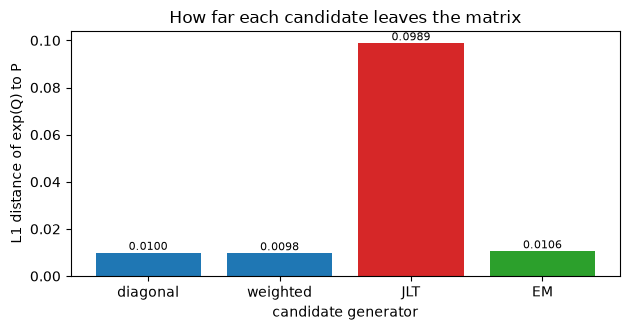

In [9]:
# Draw the L1 distance of exp(Q) to P for the four candidate generators
candidates = {"diagonal": q_diag, "weighted": q_weighted, "JLT": q_jlt, "EM": q_em}
distance = [embedding.l1_distance(P, q) for q in candidates.values()]
fig, ax = plt.subplots(figsize=(6.4, 3.4))
ax.bar(list(candidates), distance, color=["tab:blue", "tab:blue", "tab:red", "tab:green"])
for k, v in enumerate(distance):
    ax.text(k, v, f"{v:.4f}", ha="center", va="bottom", fontsize=8)
ax.set_xlabel("candidate generator")
ax.set_ylabel("L1 distance of exp(Q) to P")
ax.set_title("How far each candidate leaves the matrix")
fig.tight_layout()
plt.show()

The diagonal repair (0.00998), the weighted repair (0.00980) and the EM generator (0.01063) are within ten percent of each other, and JLT (0.0989) is a different order of magnitude. EM is not the closest although it is the only candidate that uses the original counts rather than the pooled matrix: it optimises the likelihood of the yearly tables and not the distance to their pool. The bars cannot say whether a distance of 0.01 matters, because a distance on the one-year matrix is not a distance on a PD; the next step turns it into the number a validator uses.

### Step 5: what the choice changes, the PD at one and five years

A generator gives the PD at any horizon $t$ as the default column of $\exp(tQ)$. The cohort estimator has no generator, so its five-year PD is the matrix to the fifth power.

The next cell computes, for AAA, B and CCC-C, the one- and five-year PD of each candidate and of the matrix itself.

In [10]:
# The default column at one and five years for each generator, and the matrix to the fifth power
grades_shown = (0, 5, 6)
p5 = np.linalg.matrix_power(P, 5)
header = "".join(f"{states[g] + ' 1y':>11s}{states[g] + ' 5y':>11s}" for g in grades_shown)
print(f"{'':12s}" + header)
print(f"{'P^5':12s}" + "".join(f"{100 * P[g, -1]:10.3f}%{100 * p5[g, -1]:10.3f}%" for g in grades_shown))
for name, q in candidates.items():
    one, five = expm(q)[:, -1], expm(5 * q)[:, -1]
    print(f"{name:12s}" + "".join(f"{100 * one[g]:10.3f}%{100 * five[g]:10.3f}%" for g in grades_shown))

                 AAA 1y     AAA 5y       B 1y       B 5y   CCC-C 1y   CCC-C 5y
P^5              0.000%     0.102%     1.173%     8.214%     8.068%    25.298%
diagonal         0.007%     0.127%     1.173%     8.192%     8.054%    25.145%
weighted         0.007%     0.126%     1.171%     8.176%     8.019%    25.088%
JLT              0.007%     0.138%     1.466%     9.063%     8.217%    26.183%
EM               0.007%     0.123%     1.173%     8.214%     8.062%    25.266%


The next cell draws the five-year PD of AAA and of CCC-C under each candidate, with the matrix to the fifth power as a dashed line.

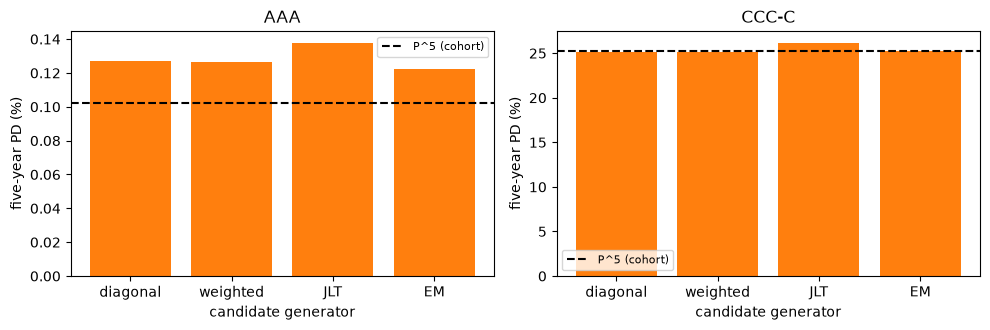

In [11]:
# Draw the five-year PD of AAA and CCC-C under each candidate, against the matrix to the fifth power
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for ax, g in zip(axes, (0, 6)):
    values = [100 * expm(5 * q)[g, -1] for q in candidates.values()]
    ax.bar(list(candidates), values, color="tab:orange")
    ax.axhline(100 * p5[g, -1], color="black", linestyle="--", label="P^5 (cohort)")
    ax.set_xlabel("candidate generator")
    ax.set_ylabel("five-year PD (%)")
    ax.set_title(states[g])
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

At one year the generators give B and CCC-C the matrix's PD to within 0.05 points for the diagonal, weighted and EM candidates, and 1.47% against 1.17% for B under JLT. At five years the spread opens: CCC-C is 25.30% by the matrix to the fifth power, 25.15% by the diagonal repair, 25.09% by the weighted one, 25.27% by EM and 26.18% by JLT, a point of PD that is part of the answer and not noise. AAA shows the other effect: the matrix gives it exactly zero at one year, and every generator gives it a small positive PD that grows to about 0.12% to 0.14% at five years, because a generator chains the rare moves down the scale. The panels do not say which of these is the true PD; only a known truth can, as in notebook 02.

### Step 6: against the printed distances of Israel et al.

The paper prints the L1 distance of each repair on three agency matrices (S&P 1981 to 1991, Moody's 1980 to 1998, S&P 1999), nine numbers. The case recomputes them from the printed matrices and commits both, with a rule: a recomputed value agrees when it lies within half a unit of the print's last digit.

The next cell prints the nine rows, with the engine's recomputation and the rule's verdict, and the explanation of the one that does not agree.

In [12]:
# The nine printed distances beside the engine's recomputation held in the artifact
irw = published["outputs"]["irw"]
print(f"{'matrix':20s}{'repair':>12s}{'printed':>12s}{'recomputed':>14s}{'agrees':>10s}")
for r in irw["rows"]:
    print(f"{r['matrix']:20s}{r['method']:>12s}{r['printed']:12.6f}{r['recomputed']:14.6f}{str(r['agrees']):>10s}")
miss = [r for r in irw["rows"] if not r["agrees"]][0]
print("the one that does not agree:", miss["matrix"], miss["method"], "| printed", miss["printed"],
      "| from the printed JLT generator:", round(irw["jlt_from_printed_generator"], 4))

matrix                    repair     printed    recomputed    agrees
S&P 1981-1991                jlt    0.116900      0.116477     False
S&P 1981-1991           diagonal    0.002736      0.002736      True
S&P 1981-1991           weighted    0.002686      0.002686      True
Moody's 1980-1998            jlt    0.100047      0.100047      True
Moody's 1980-1998       diagonal    0.001401      0.001401      True
Moody's 1980-1998       weighted    0.001371      0.001371      True
S&P 1999                     jlt    0.103516      0.103516      True
S&P 1999                diagonal    0.001096      0.001096      True
S&P 1999                weighted    0.001088      0.001088      True
the one that does not agree: S&P 1981-1991 jlt | printed 0.1169 | from the printed JLT generator: 0.1169


Eight of the nine distances are reproduced to the printed digits. The ninth, JLT on S&P 1981 to 1991, prints 0.1169 where equation (3) on the printed matrix gives 0.1165, and the disagreement is the paper's own arithmetic: 0.1169 follows from the printed four-digit JLT generator, not from the printed matrix, and starting from that generator the engine gets 0.1169 as well. The case reports the gap and carries the explanation instead of fitting a number. The matrices of the paper are not committed, only these distances, so this step reads the comparison and cannot rerun it.

## Results

**Answer:** no. The pooled S&P matrix has no exact generator: S = 0.121 is below one, but condition (c) of Theorem 3 holds in six pairs and the matrix breaks monotonicity in four cells; the log series, exact to 1.4e-15, has nine negative off-diagonal entries, the most negative CCC-C to BB (-0.0036). The repair that keeps its exponential closest to the matrix is the weighted adjustment, with an L1 distance of 0.00980, ahead of the diagonal repair (0.00998), the EM generator (0.01063) and JLT (0.0989). The choice moves a five-year PD: CCC-C is 25.30% by the matrix to the fifth power and 26.18% by JLT.

- **No exact generator.** The determinant, 0.3364, sits between zero and the product of the diagonal, 0.3471, so conditions (a) and (b) of Theorem 3 do not exclude one, and every diagonal entry is above 1/2.
- **The five-year PD depends on the repair.** CCC-C is 25.15% under the diagonal repair, 25.09% under the weighted one and 25.27% under EM; AAA goes from exactly 0 at one year in the matrix to 0.007% under every generator.
- **Against the print.** Eight of the nine L1 distances Israel et al. print are reproduced. The ninth, JLT on S&P 1981 to 1991, prints 0.1169 where equation (3) on the printed matrix gives 0.1165; starting from the paper's printed four-digit generator the same distance is 0.1169.

What this notebook does not show: whether the Markov model fits the data at all (notebook 04), or a generator with macroeconomic conditioning (notebook 08).

## Summary

- A one-year matrix has an exact generator only if the log series converges, no condition of Theorem 3 excludes it and the result has non-negative off-diagonal entries; an empirical matrix rarely does.
- The diagonal and weighted repairs and the EM generator stay near the matrix; JLT is ten times further here.
- The generator is part of the PD at a longer horizon: the five-year PD of CCC-C moves by about a point across the candidates, and a grade with a zero one-year PD gets a positive one.
- A recomputation that does not match a print is reported with its explanation, never adjusted.

**What to try next.** Compute the log series of the 2000 cohort matrix of notebook 01 and see how many negative entries a single year gives; then read notebook 04.

## References

- ESMA, CEREP publication of credit rating agency ratings and transitions. https://registers.esma.europa.eu/cerep-publication/
- Israel, R. B., Rosenthal, J. S. and Wei, J. Z. (2001), Finding generators for Markov chains via empirical transition matrices, with applications to credit ratings, Mathematical Finance 11(2), 245-265, Theorems 1 to 3, Lemma 1 and equations (2), (2') and (3). https://doi.org/10.1111/1467-9965.00114
- Jarrow, R. A., Lando, D. and Turnbull, S. M. (1997), A Markov model for the term structure of credit risk spreads, Review of Financial Studies 10(2), as cited by the engine for equation (3) and Lemma 1.
- Bladt, M. and Sorensen, M. (2005), Journal of the Royal Statistical Society B 67(3), and Smith, A. and dos Reis, G. (2018), Quantitative Finance, doi 10.1080/14697688.2017.1383627, for the EM generator.